In [9]:
'''Develop and deploy a secure, scalable REST API using frameworks like FastAPI or
 Flask for serving real-time admission predictions, handling concurrent requests, and maintaining low-latency responses.'''

'Develop and deploy a secure, scalable REST API using frameworks like FastAPI or\n Flask for serving real-time admission predictions, handling concurrent requests, and maintaining low-latency responses.'

In [10]:
# import required libraries
import time
from concurrent.futures import ThreadPoolExecutor
from flask import Flask, request, jsonify
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [11]:
# load dataset and split features
df = pd.read_csv('Adm.csv')
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('features shape:', X_train.shape)

features shape: (800, 7)


In [12]:
# train and serialize regression model
model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)
print('r2 score:', round(r2_score(y_test, preds), 4))
print('mse:', round(mean_squared_error(y_test, preds), 4))

joblib.dump(model, 'adm_model.joblib')

r2 score: 0.9044
mse: 0.001


['adm_model.joblib']

In [13]:
# create secure rest api service
app = Flask('admission_api')
loaded_model = joblib.load('adm_model.joblib')
API_KEY = 'adm_secure_token_2026'

@app.route('/health', methods=['GET'])
def health():
    return jsonify({'status': 'healthy', 'service': 'admission_prediction'})

@app.route('/predict', methods=['POST'])
def predict():
    api_key = request.headers.get('X-API-Key')
    if api_key != API_KEY:
        return jsonify({'error': 'unauthorized access'}), 401
    
    data = request.get_json()
    input_data = np.array([[
        data['GRE Score'],
        data['TOEFL Score'],
        data['University Rating'],
        data['SOP'],
        data['LOR'],
        data['CGPA'],
        data['Research']
    ]])
    prediction = float(loaded_model.predict(input_data)[0])
    return jsonify({'chance_of_admit': round(prediction, 4)})

In [14]:
# test rest api endpoints
client = app.test_client()

resp_health = client.get('/health')
print('health response:', resp_health.json)

sample_payload = {
    'GRE Score': 324,
    'TOEFL Score': 108,
    'University Rating': 4,
    'SOP': 4.0,
    'LOR': 4.5,
    'CGPA': 8.87,
    'Research': 1
}

resp_unauth = client.post('/predict', json=sample_payload)
print('unauthorized status code:', resp_unauth.status_code)

resp_auth = client.post('/predict', headers={'X-API-Key': API_KEY}, json=sample_payload)
print('authorized response:', resp_auth.status_code, resp_auth.json)

health response: {'service': 'admission_prediction', 'status': 'healthy'}
unauthorized status code: 401
authorized response: 200 {'chance_of_admit': 0.8024}


In [15]:
# benchmark concurrent requests and latency
def send_request(idx):
    start_time = time.perf_counter()
    resp = client.post('/predict', headers={'X-API-Key': API_KEY}, json=sample_payload)
    latency_ms = (time.perf_counter() - start_time) * 1000
    return latency_ms, resp.status_code

total_requests = 100
with ThreadPoolExecutor(max_workers=10) as executor:
    results = list(executor.map(send_request, range(total_requests)))

latencies = [res[0] for res in results]
print('total concurrent requests:', len(latencies))
print('average latency ms:', round(np.mean(latencies), 2))
print('p95 latency ms:', round(np.percentile(latencies, 95), 2))
print('max latency ms:', round(np.max(latencies), 2))

total concurrent requests: 100
average latency ms: 60.78
p95 latency ms: 104.0
max latency ms: 139.73


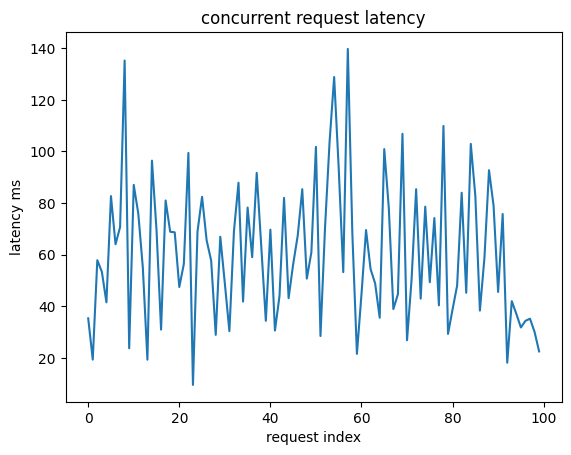

In [16]:
# plot request latency
plt.plot(latencies)
plt.title('concurrent request latency')
plt.xlabel('request index')
plt.ylabel('latency ms')
plt.show()